In [1]:
import pandas as pd
import numpy as np
import yfinance as yf

import matplotlib.pyplot as plt

from xgboost import XGBRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    accuracy_score
)

import joblib
import json
import os

In [3]:
tickers = [
    "AAPL",
    "^GSPC",
    "^IXIC",
    "^VIX",
    "XLK"
]

data = yf.download(
    tickers,
    start="2018-01-01",
    end="2026-10-03",
    auto_adjust=False
)

data.head()

[*********************100%***********************]  5 of 5 completed


Price       Adj Close                                                 Close  \
Ticker           AAPL        XLK        ^GSPC        ^IXIC  ^VIX       AAPL   
Date                                                                          
2018-01-02  40.232384  29.802570  2695.810059  7006.899902  9.77  43.064999   
2018-01-03  40.225365  30.051153  2713.060059  7065.529785  9.15  43.057499   
2018-01-04  40.412216  30.203056  2723.989990  7077.910156  9.22  43.257500   
2018-01-05  40.872326  30.520704  2743.149902  7136.560059  9.22  43.750000   
2018-01-08  40.720516  30.635792  2747.709961  7157.390137  9.52  43.587502   

Price                                                  ...       Open  \
Ticker            XLK        ^GSPC        ^IXIC  ^VIX  ...       AAPL   
Date                                                   ...              
2018-01-02  32.369999  2695.810059  7006.899902  9.77  ...  42.540001   
2018-01-03  32.639999  2713.060059  7065.529785  9.15  ...  43.132500   
2018-01-04  32.805000  2723.989990  7077.910156  9.22  ...  43.134998   
2018-01-05  33.150002  2743.149902  7136.560059  9.22  ...  43.360001   
2018-01-08  33.275002  2747.709961  7157.390137  9.52  ...  43.587502   

Price                                                        Volume  \
Ticker            XLK        ^GSPC        ^IXIC   ^VIX         AAPL   
Date                                                                  
2018-01-02  32.105000  2683.729980  6937.649902  10.95  102223600.0   
2018-01-03  32.430000  2697.850098  7017.069824   9.56  118071600.0   
2018-01-04  32.770000  2719.310059  7089.500000   9.01   89738400.0   
2018-01-05  32.974998  2731.330078  7105.740234   9.10   94640000.0   
2018-01-08  33.134998  2742.669922  7135.379883   9.61   82271200.0   

Price                                                    
Ticker             XLK         ^GSPC         ^IXIC ^VIX  
Date                                                     
2018-01-02  27445600.0  3.397430e+09  1.929700e+09    0  
2018-01-03  22663600.0  3.544030e+09  2.173130e+09    0  
2018-01-04  21493200.0  3.697340e+09  2.103220e+09    0  
2018-01-05  19356000.0  3.239280e+09  2.024000e+09    0  
2018-01-08  13467800.0  3.246160e+09  2.055010e+09    0  

[5 rows x 30 columns]

In [4]:
close = data["Close"].copy()

close.head()

Ticker,AAPL,XLK,^GSPC,^IXIC,^VIX
Date,,,,,
2018-01-02,43.064999,32.369999,2695.810059,7006.899902,9.77
2018-01-03,43.057499,32.639999,2713.060059,7065.529785,9.15
2018-01-04,43.257500,32.805000,2723.989990,7077.910156,9.22
2018-01-05,43.750000,33.150002,2743.149902,7136.560059,9.22
2018-01-08,43.587502,33.275002,2747.709961,7157.390137,9.52


In [5]:
close.columns = [
    "AAPL",
    "SP500",
    "NASDAQ",
    "VIX",
    "XLK"
]

close.head()

,AAPL,SP500,NASDAQ,VIX,XLK
Date,,,,,
2018-01-02,43.064999,32.369999,2695.810059,7006.899902,9.77
2018-01-03,43.057499,32.639999,2713.060059,7065.529785,9.15
2018-01-04,43.257500,32.805000,2723.989990,7077.910156,9.22
2018-01-05,43.750000,33.150002,2743.149902,7136.560059,9.22
2018-01-08,43.587502,33.275002,2747.709961,7157.390137,9.52


In [6]:
print(close.shape)

print("\nMissing values:")
print(close.isnull().sum())

print("\nDate range:")
print(close.index.min())
print(close.index.max())

(2202, 5)

Missing values:
AAPL      2
SP500     2
NASDAQ    2
VIX       2
XLK       0
dtype: int64

Date range:
2018-01-02 00:00:00
2026-10-02 00:00:00


In [8]:
close["Target_Return"] = (
    close["AAPL"].shift(-1) / close["AAPL"] - 1
)

In [9]:
close[["AAPL", "Target_Return"]].head(10)

,AAPL,Target_Return
Date,,
2018-01-02,43.064999,-0.000174
2018-01-03,43.057499,0.004645
2018-01-04,43.257500,0.011385
2018-01-05,43.750000,-0.003714
2018-01-08,43.587502,-0.000115
2018-01-09,43.582500,-0.000229
2018-01-10,43.572498,0.005680
2018-01-11,43.820000,0.010326
2018-01-12,44.272499,-0.005082


In [10]:
close["Lag_1"] = close["AAPL"].shift(1)
close["Lag_2"] = close["AAPL"].shift(2)
close["Lag_3"] = close["AAPL"].shift(3)
close["Lag_7"] = close["AAPL"].shift(7)

In [11]:
close["Return"] = close["AAPL"].pct_change()

In [12]:
close[["AAPL", "Return"]].head(10)

,AAPL,Return
Date,,
2018-01-02,43.064999,NaN
2018-01-03,43.057499,-0.000174
2018-01-04,43.257500,0.004645
2018-01-05,43.750000,0.011385
2018-01-08,43.587502,-0.003714
2018-01-09,43.582500,-0.000115
2018-01-10,43.572498,-0.000229
2018-01-11,43.820000,0.005680
2018-01-12,44.272499,0.010326


In [13]:
close["Volatility_7"] = (
    close["Return"]
    .rolling(7)
    .std()
)

In [14]:
close["MA_7"] = (
    close["AAPL"]
    .shift(1)
    .rolling(7)
    .mean()
)

close["MA_14"] = (
    close["AAPL"]
    .shift(1)
    .rolling(14)
    .mean()
)

close["MA_30"] = (
    close["AAPL"]
    .shift(1)
    .rolling(30)
    .mean()
)

In [15]:
close["MA7_Ratio"] = (
    close["AAPL"] / close["MA_7"]
)

close["MA14_Ratio"] = (
    close["AAPL"] / close["MA_14"]
)

close["MA30_Ratio"] = (
    close["AAPL"] / close["MA_30"]
)

In [16]:
close["SMA_20"] = (
    close["AAPL"]
    .shift(1)
    .rolling(20)
    .mean()
)

close["SMA_50"] = (
    close["AAPL"]
    .shift(1)
    .rolling(50)
    .mean()
)

close["EMA_12"] = (
    close["AAPL"]
    .shift(1)
    .ewm(span=12, adjust=False)
    .mean()
)

close["EMA_26"] = (
    close["AAPL"]
    .shift(1)
    .ewm(span=26, adjust=False)
    .mean()
)

In [17]:
close["SMA20_Ratio"] = (
    close["AAPL"] / close["SMA_20"]
)

close["SMA50_Ratio"] = (
    close["AAPL"] / close["SMA_50"]
)

close["MACD"] = (
    close["EMA_12"] - close["EMA_26"]
)

In [18]:
rolling_mean = (
    close["AAPL"]
    .shift(1)
    .rolling(20)
    .mean()
)

rolling_std = (
    close["AAPL"]
    .shift(1)
    .rolling(20)
    .std()
)

close["BB_Upper"] = (
    rolling_mean + 2 * rolling_std
)

close["BB_Lower"] = (
    rolling_mean - 2 * rolling_std
)

close["BB_Position"] = (
    (close["AAPL"] - close["BB_Lower"]) /
    (close["BB_Upper"] - close["BB_Lower"])
)

In [19]:
delta = close["AAPL"].diff()

gain = delta.clip(lower=0)
loss = -delta.clip(upper=0)

avg_gain = (
    gain
    .shift(1)
    .rolling(14)
    .mean()
)

avg_loss = (
    loss
    .shift(1)
    .rolling(14)
    .mean()
)

rs = avg_gain / avg_loss

close["RSI_14"] = (
    100 - (100 / (1 + rs))
)

In [20]:
close["SP500_Return"] = (
    close["SP500"].pct_change()
)

close["NASDAQ_Return"] = (
    close["NASDAQ"].pct_change()
)

close["VIX_Return"] = (
    close["VIX"].pct_change()
)

close["XLK_Return"] = (
    close["XLK"].pct_change()
)

In [21]:
close["AAPL_vs_SP500"] = (
    close["Return"] - close["SP500_Return"]
)

close["AAPL_vs_NASDAQ"] = (
    close["Return"] - close["NASDAQ_Return"]
)

close["AAPL_vs_XLK"] = (
    close["Return"] - close["XLK_Return"]
)

In [22]:
close["SP500_Momentum_5"] = (
    close["SP500"].pct_change(5)
)

close["NASDAQ_Momentum_5"] = (
    close["NASDAQ"].pct_change(5)
)

close["XLK_Momentum_5"] = (
    close["XLK"].pct_change(5)
)

In [23]:
close["VIX_Level"] = close["VIX"]

In [24]:
features = [
    # AAPL features
    "Lag_1",
    "Lag_2",
    "Lag_3",
    "Lag_7",
    "Return",
    "Volatility_7",
    "MA7_Ratio",
    "MA14_Ratio",
    "MA30_Ratio",
    "SMA20_Ratio",
    "SMA50_Ratio",
    "MACD",
    "BB_Position",
    "RSI_14",

    # Market features
    "SP500_Return",
    "NASDAQ_Return",
    "VIX_Return",
    "XLK_Return",
    "AAPL_vs_SP500",
    "AAPL_vs_NASDAQ",
    "AAPL_vs_XLK",
    "SP500_Momentum_5",
    "NASDAQ_Momentum_5",
    "XLK_Momentum_5",
    "VIX_Level"
]

print("Number of features:", len(features))

Number of features: 25


In [25]:
X = close[features]

y = close["Target_Return"]

In [26]:
print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (2202, 25)
y shape: (2202,)


In [27]:
dataset = pd.concat([X, y], axis=1)

dataset = dataset.dropna()

print("Final dataset shape:", dataset.shape)

Final dataset shape: (2079, 26)


In [28]:
X = dataset[features]
y = dataset["Target_Return"]

print("X:", X.shape)
print("y:", y.shape)

X: (2079, 25)
y: (2079,)


In [29]:
print("Total missing values:", X.isnull().sum().sum())
print("Target missing values:", y.isnull().sum())

Total missing values: 0
Target missing values: 0


In [30]:
split = int(len(X) * 0.8)

X_train = X.iloc[:split]
X_test = X.iloc[split:]

y_train = y.iloc[:split]
y_test = y.iloc[split:]

In [31]:
print("Training period:")
print(X_train.index.min(), "to", X_train.index.max())

print("\nTesting period:")
print(X_test.index.min(), "to", X_test.index.max())

Training period:
2018-03-15 00:00:00 to 2024-10-22 00:00:00

Testing period:
2024-10-23 00:00:00 to 2026-09-03 00:00:00


In [32]:
baseline_pred = np.zeros(len(y_test))

In [33]:
baseline_mae = mean_absolute_error(
    y_test,
    baseline_pred
)

baseline_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        baseline_pred
    )
)

baseline_r2 = r2_score(
    y_test,
    baseline_pred
)

print("Naive Baseline")
print("----------------")
print("MAE :", baseline_mae)
print("RMSE:", baseline_rmse)
print("R²  :", baseline_r2)

Naive Baseline
----------------
MAE : 0.011789401369796079
RMSE: 0.01803917307644376
R²  : -0.00260177801343775


In [34]:
from xgboost import XGBRegressor

improved_xgb = XGBRegressor(
    n_estimators=200,
    learning_rate=0.03,
    max_depth=3,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42
)

In [35]:
improved_xgb.fit(
    X_train,
    y_train
)

,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,0.8
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Sequence[str] | None.. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [36]:
pred = improved_xgb.predict(X_test)

print(pred[:10])

[ 0.00177722  0.00191375  0.00171227  0.00064525  0.00170193  0.00063242
 -0.00399797 -0.0008791  -0.0016011  -0.0012929 ]


In [37]:
mae = mean_absolute_error(
    y_test,
    pred
)

rmse = np.sqrt(
    mean_squared_error(
        y_test,
        pred
    )
)

r2 = r2_score(
    y_test,
    pred
)

print("Improved XGBoost")
print("----------------")
print("MAE :", mae)
print("RMSE:", rmse)
print("R²  :", r2)

Improved XGBoost
----------------
MAE : 0.01211694965685545
RMSE: 0.018730015626421587
R²  : -0.08086511215828596


In [38]:
actual_direction = (
    y_test > 0
).astype(int)

predicted_direction = (
    pred > 0
).astype(int)

directional_accuracy = accuracy_score(
    actual_direction,
    predicted_direction
)

print(
    f"Directional Accuracy: "
    f"{directional_accuracy * 100:.2f}%"
)

Directional Accuracy: 51.92%


In [39]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    actual_direction,
    predicted_direction
)

print(cm)

[[ 63 130]
 [ 70 153]]


In [40]:
prediction_correlation = np.corrcoef(
    y_test,
    pred
)[0, 1]

print(
    "Prediction correlation:",
    prediction_correlation
)

Prediction correlation: 0.04322120173272772


In [41]:
print("Actual mean:", y_test.mean())
print("Predicted mean:", pred.mean())

print("Actual std:", y_test.std())
print("Predicted std:", pred.std())

Actual mean: 0.0009189407485355151
Predicted mean: 0.00043959735
Actual std: 0.01803744447237074
Predicted std: 0.0059383833


In [42]:
importance = pd.Series(
    improved_xgb.feature_importances_,
    index=features
).sort_values(ascending=False)

print(importance)

MA7_Ratio            0.076925
Volatility_7         0.053674
SMA50_Ratio          0.049568
MA30_Ratio           0.048177
NASDAQ_Momentum_5    0.047727
AAPL_vs_NASDAQ       0.046684
Return               0.046633
SMA20_Ratio          0.045210
MA14_Ratio           0.042615
VIX_Return           0.041626
XLK_Momentum_5       0.041007
NASDAQ_Return        0.038992
AAPL_vs_XLK          0.038937
XLK_Return           0.038931
AAPL_vs_SP500        0.038107
VIX_Level            0.036051
RSI_14               0.035534
SP500_Return         0.035129
Lag_2                0.030343
Lag_7                0.030268
SP500_Momentum_5     0.030184
MACD                 0.029590
BB_Position          0.028002
Lag_3                0.026022
Lag_1                0.024065
dtype: float32


In [43]:
print(
    importance.head(15)
)

MA7_Ratio            0.076925
Volatility_7         0.053674
SMA50_Ratio          0.049568
MA30_Ratio           0.048177
NASDAQ_Momentum_5    0.047727
AAPL_vs_NASDAQ       0.046684
Return               0.046633
SMA20_Ratio          0.045210
MA14_Ratio           0.042615
VIX_Return           0.041626
XLK_Momentum_5       0.041007
NASDAQ_Return        0.038992
AAPL_vs_XLK          0.038937
XLK_Return           0.038931
AAPL_vs_SP500        0.038107
dtype: float32


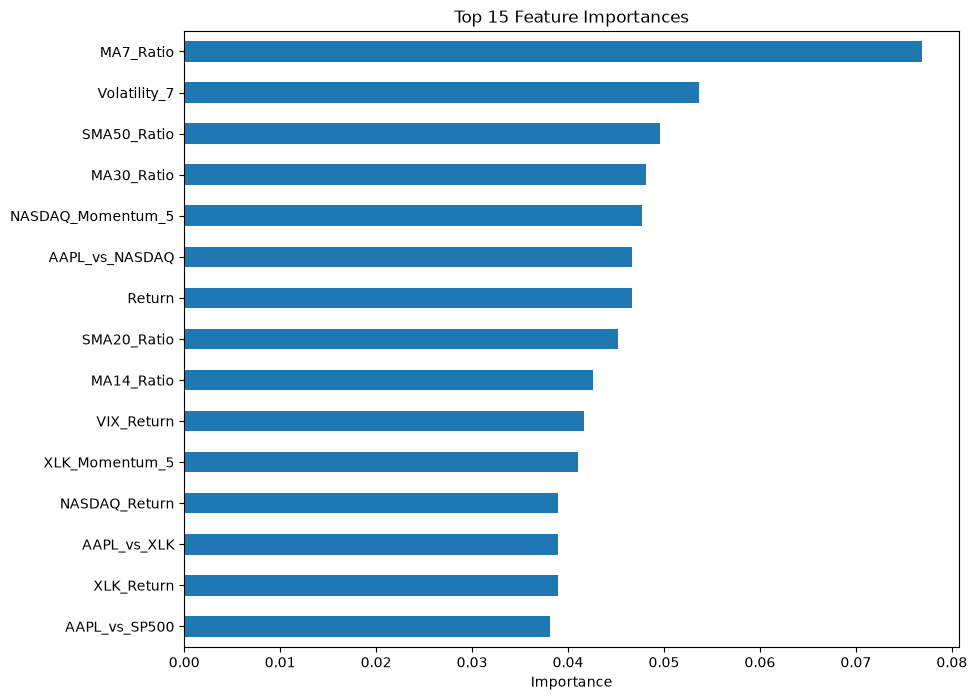

In [44]:
plt.figure(figsize=(10, 8))

importance.head(15).sort_values().plot(
    kind="barh"
)

plt.title("Top 15 Feature Importances")
plt.xlabel("Importance")
plt.show()

In [45]:
comparison = pd.DataFrame({
    "Model": [
        "Naive Baseline",
        "Old XGBoost",
        "Improved XGBoost"
    ],

    "MAE": [
        baseline_mae,
        0.0127700307,
        mae
    ],

    "RMSE": [
        baseline_rmse,
        0.0196445898,
        rmse
    ],

    "R2": [
        baseline_r2,
        -0.0825595628,
        r2
    ],

    "Directional Accuracy": [
        np.nan,
        0.5225653,
        directional_accuracy
    ]
})

comparison

,Model,MAE,RMSE,R2,Directional Accuracy
0,Naive Baseline,0.011789,0.018039,-0.002602,NaN
1,Old XGBoost,0.012770,0.019645,-0.082560,0.522565
2,Improved XGBoost,0.012117,0.018730,-0.080865,0.519231


In [56]:
import os
import joblib

os.makedirs("model", exist_ok=True)

joblib.dump(
    improved_xgb,
    r"C:\Users\nkush\OneDrive\Desktop\PricePulse\models\pricepulse_improved_xgb_model.joblib"
)

print("Model saved successfully.")

Model saved successfully.


In [50]:
joblib.dump(
    features,
    r"C:\Users\nkush\OneDrive\Desktop\PricePulse\modelspricepulse_improved_features.joblib"
)

print("Features saved successfully.")

Features saved successfully.


In [52]:
import json

metadata = {
    "project": "PricePulse",
    "ticker": "AAPL",
    "target": "next_day_return",

    "model": "XGBoost Regressor",

    "hyperparameters": {
        "n_estimators": 200,
        "learning_rate": 0.03,
        "max_depth": 3,
        "subsample": 0.8,
        "colsample_bytree": 0.8,
        "random_state": 42
    },

    "features": features,

    "evaluation": {
        "mae": float(mae),
        "rmse": float(rmse),
        "r2": float(r2),
        "directional_accuracy": float(directional_accuracy)
    },

    "baseline": {
        "mae": float(baseline_mae),
        "rmse": float(baseline_rmse),
        "r2": float(baseline_r2)
    }
}

with open(
    r"C:\Users\nkush\OneDrive\Desktop\PricePulse\modelspricepulse_metadata.json",
    "w"
) as file:
    json.dump(
        metadata,
        file,
        indent=4
    )

print("Metadata saved successfully.")

Metadata saved successfully.


In [57]:
import joblib

joblib.dump(
    features,
    r"C:\Users\nkush\OneDrive\Desktop\PricePulse\models\pricepulse_improved_features.joblib"
)

print("Features saved successfully.")

Features saved successfully.


In [58]:
import json

metadata = {
    "project": "PricePulse",
    "ticker": "AAPL",
    "target": "next_day_return",
    "model": "XGBoost Regressor",
    "hyperparameters": {
        "n_estimators": 200,
        "learning_rate": 0.03,
        "max_depth": 3,
        "subsample": 0.8,
        "colsample_bytree": 0.8,
        "random_state": 42
    },
    "features": features,
    "evaluation": {
        "mae": float(mae),
        "rmse": float(rmse),
        "r2": float(r2),
        "directional_accuracy": float(directional_accuracy)
    }
}

metadata_path = r"C:\Users\nkush\OneDrive\Desktop\PricePulse\models\pricepulse_metadata.json"

with open(metadata_path, "w") as file:
    json.dump(metadata, file, indent=4)

print("Metadata saved successfully.")

Metadata saved successfully.
